In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']

listings = pd.read_csv('data/listings_clean.csv', parse_dates=date_columns)

print(listings.shape)

(4574, 73)


> **Notes: the words to remember**
>
> - **figure**: the whole picture, like a sheet of paper.
> - **axes** (`ax`): one chart on the figure, with its own x-axis and y-axis.
> - `fig, ax = plt.subplots()`: makes a new figure with one axes on it. We draw *on* the axes.
> - **histogram**: divides the values into intervals and counts how many fall in each one.
> - **bins**: the intervals of a histogram. More bins give a more detailed picture.
> - `dropna()`: removes the missing values. A chart can only draw what exists.
> - `plt.show()`: shows the picture.

What does the distribution of the price look like?

histogram

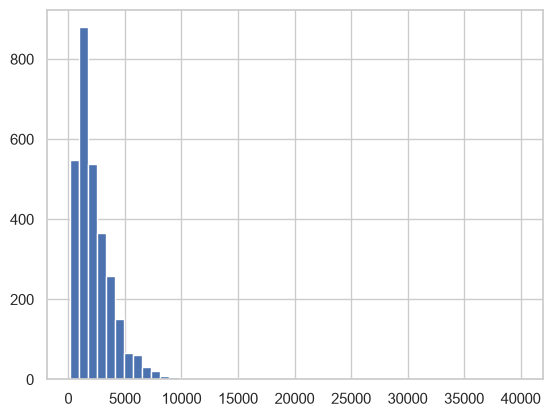

In [2]:
fig, ax = plt.subplots()

ax.hist(listings['price'].dropna(), bins=50)

plt.show()

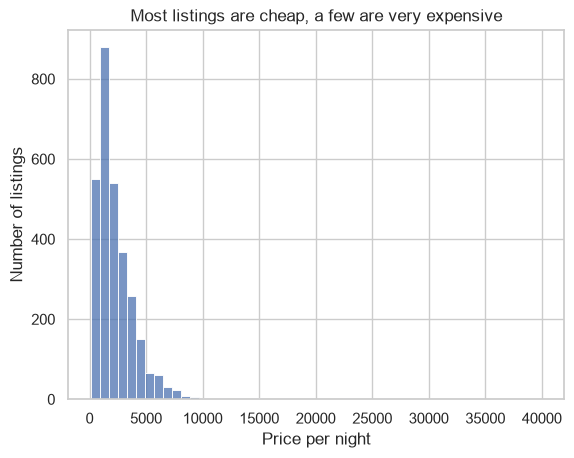

In [3]:
fig, ax = plt.subplots()

sns.histplot(data=listings, x='price', bins=50, ax=ax)

ax.set_title('Most listings are cheap, a few are very expensive')
ax.set_xlabel('Price per night')
ax.set_ylabel('Number of listings')

plt.show()


The histogram: see the shape of the price

In [4]:
q1 = listings['price'].quantile(0.25)
q3 = listings['price'].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)

listings['price_outlier'] = listings['price'] > upper

print(round(upper, 1), listings['price_outlier'].sum())

5902.8 132


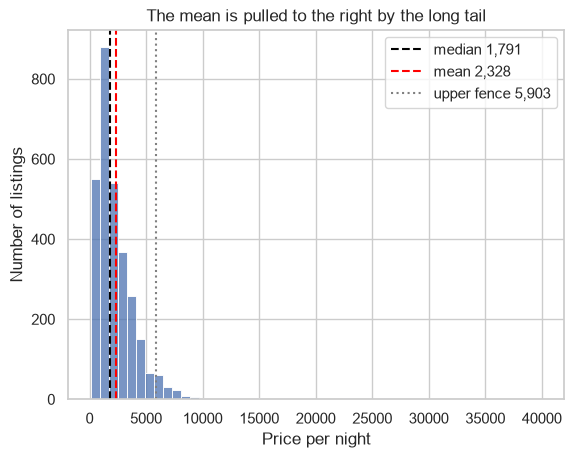

In [5]:
median = listings['price'].median()
mean = listings['price'].mean()

fig, ax = plt.subplots()

sns.histplot(data=listings, x='price', bins=50, ax=ax)

ax.axvline(median, color='black', linestyle='--', label=f'median {median:,.0f}')
ax.axvline(mean, color='red', linestyle='--', label=f'mean {mean:,.0f}')
ax.axvline(upper, color='gray', linestyle=':', label=f'upper fence {upper:,.0f}')


ax.set_title('The mean is pulled to the right by the long tail')
ax.set_xlabel('Price per night')
ax.set_ylabel('Number of listings')
ax.legend()

plt.show()



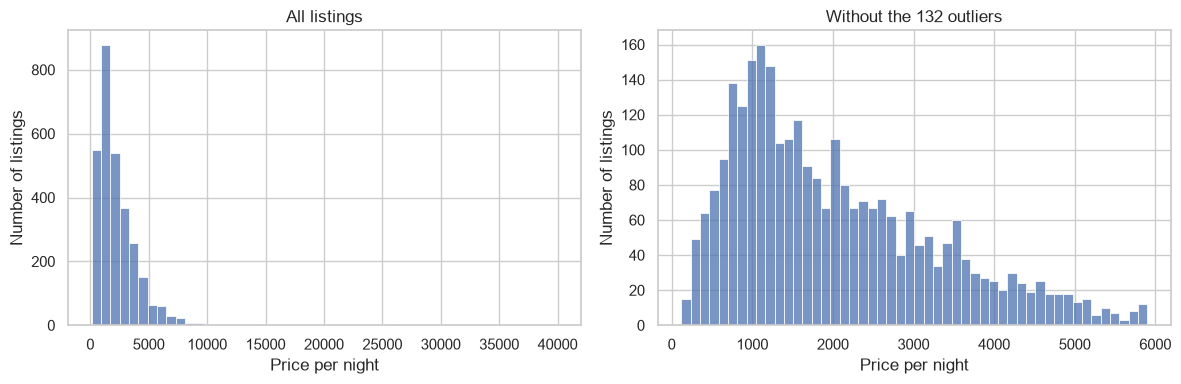

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=listings, x='price', bins=50, ax=axes[0])
sns.histplot(data=listings[~listings['price_outlier']], x='price', bins=50, ax=axes[1])

axes[0].set_title('All listings')
axes[1].set_title('Without the 132 outliers')

for ax in axes:
    ax.set_xlabel('Price per night')
    ax.set_ylabel('Number of listings')

plt.tight_layout()

plt.show()

## The boxplot: see the outliers

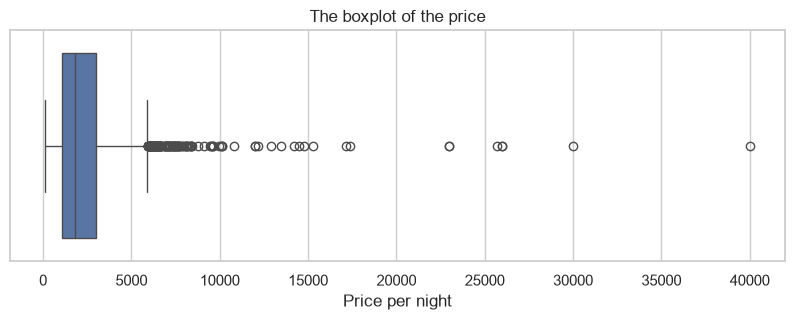

In [8]:
fig, ax = plt.subplots(figsize=(10, 3))

sns.boxplot(data=listings, x='price', ax=ax)

ax.set_title('The boxplot of the price')
ax.set_xlabel('Price per night')

plt.show()

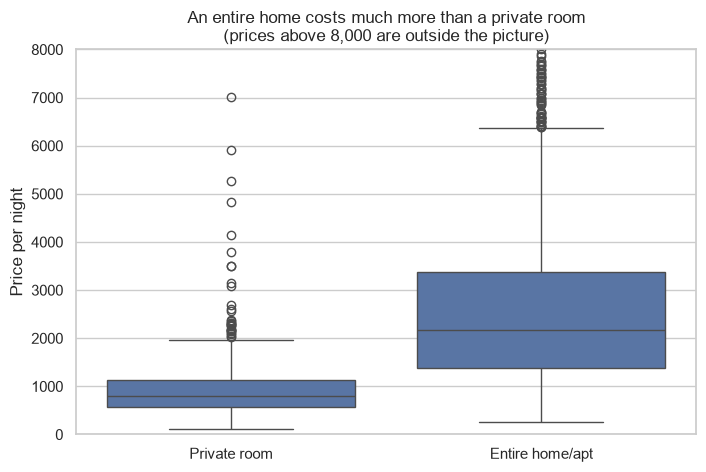

In [9]:
two_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=two_types, x= 'room_type', y='price', ax=ax)

ax.set_ylim(0,8000)
ax.set_title('An entire home costs much more than a private room\n(prices above 8,000 are outside the picture)')
ax.set_xlabel('')
ax.set_ylabel('Price per night')

plt.show()

## Bar chart: compare the neighbourhoods

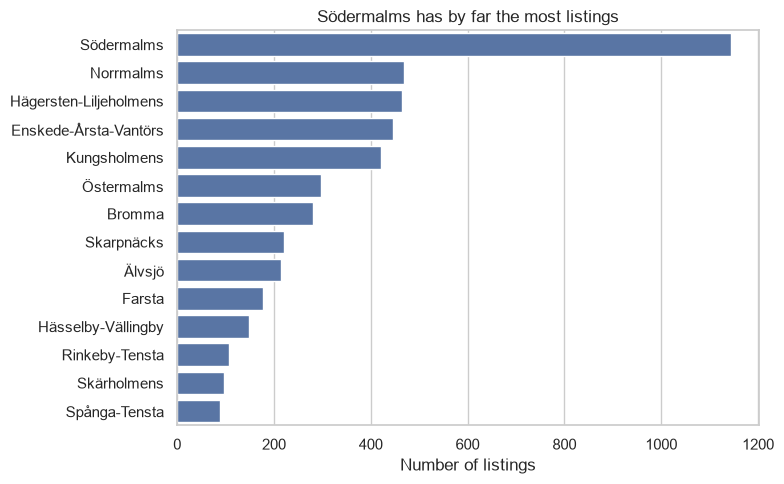

In [11]:
order = listings['neighbourhood_cleansed'].value_counts().index

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(data=listings, y='neighbourhood_cleansed', order=order, ax=ax)

ax.set_title('Södermalms has by far the most listings')
ax.set_xlabel('Number of listings')
ax.set_ylabel('')

plt.tight_layout()
plt.show()

In [12]:
by_area = (
    listings.groupby('neighbourhood_cleansed')['price']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
    .reset_index()
)

by_area['label'] = by_area['neighbourhood_cleansed'] + '(' + by_area['count'].astype(str) + ')' # Farsta(113)

by_area.head(3)

,neighbourhood_cleansed,median,count,label
0,Farsta,2213.88,113,Farsta(113)
1,Södermalms,2119.10,714,Södermalms(714)
2,Bromma,2089.00,191,Bromma(191)


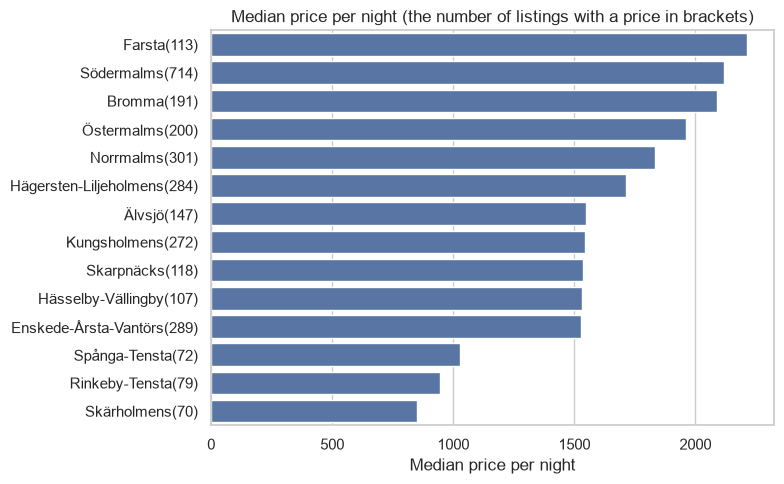

In [13]:
fif, ax = plt.subplots(figsize=(8, 5))

sns.barplot(data=by_area, x='median', y='label', ax=ax)

ax.set_title('Median price per night (the number of listings with a price in brackets)')
ax.set_xlabel('Median price per night')
ax.set_ylabel('')

plt.tight_layout()
plt.show()

## The scatter plot: how two columns move together

16 listings are above the top of the picture


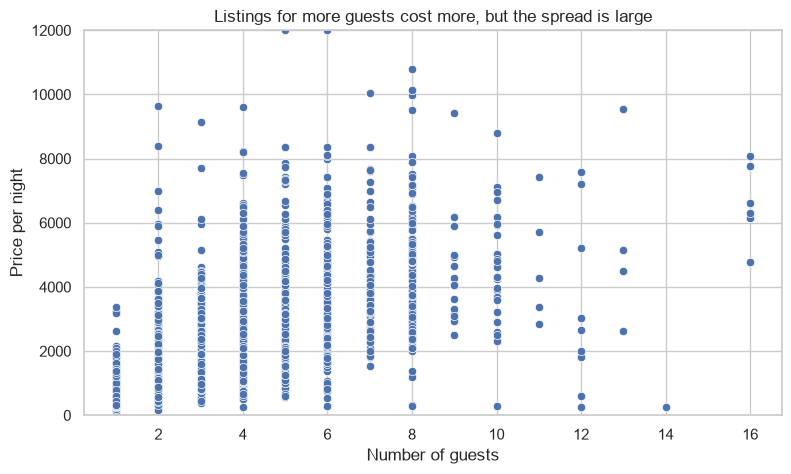

In [14]:
print((listings['price'] > 12000).sum(), 'listings are above the top of the picture')

fig, ax = plt.subplots(figsize=(9, 5))

sns.scatterplot(data=listings, x='accommodates', y='price', ax=ax)

ax.set_ylim(0, 12000)

ax.set_title('Listings for more guests cost more, but the spread is large')
ax.set_xlabel('Number of guests')
ax.set_ylabel('Price per night')

plt.show()

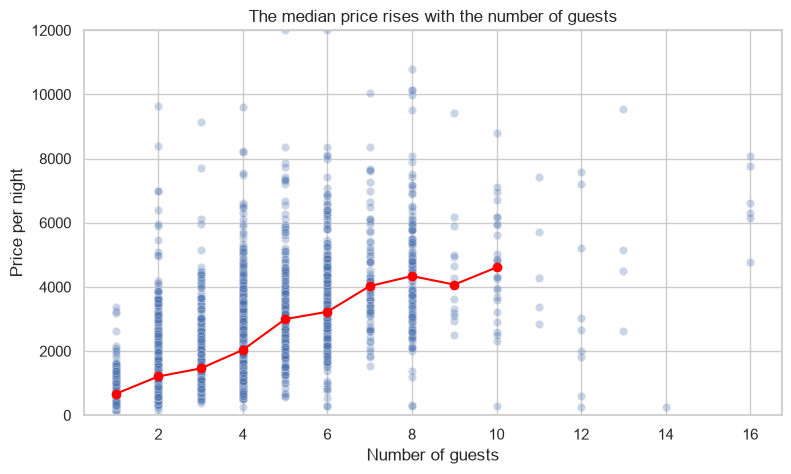

In [16]:
medians = listings.groupby('accommodates')['price'].median().head(10)

fig, ax = plt.subplots(figsize=(9, 5))

sns.scatterplot(data=listings, x='accommodates', y='price', alpha=0.3, ax=ax)

ax.plot(medians.index, medians.values, color='red', marker= 'o', label='median price (1 to 10 guests)')

ax.set_ylim(0, 12000)

ax.set_title('The median price rises with the number of guests')
ax.set_xlabel('Number of guests')
ax.set_ylabel('Price per night')

plt.show()

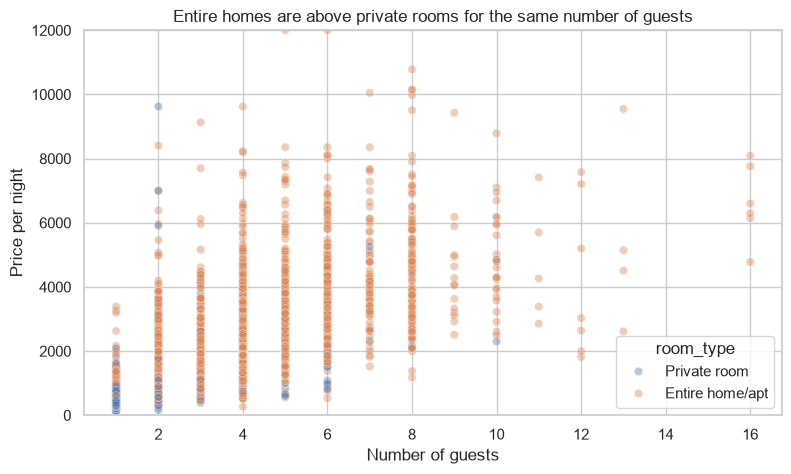

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.scatterplot(data=two_types, x='accommodates', y='price', hue='room_type', alpha=0.4, ax=ax)

ax.set_ylim(0, 12000)

ax.set_title('Entire homes are above private rooms for the same number of guests')
ax.set_xlabel('Number of guests')
ax.set_ylabel('Price per night')

plt.show()

## The heatmap and the line chart 

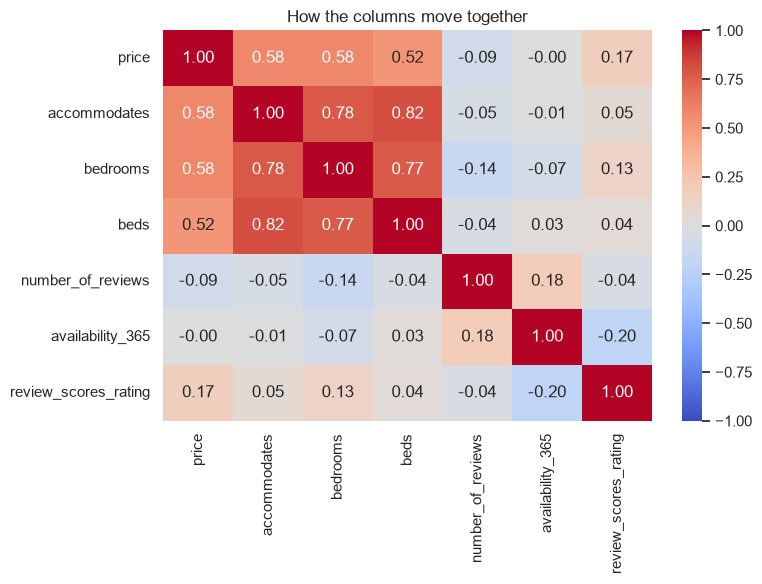

In [18]:
columns = ['price', 'accommodates', 'bedrooms', 'beds', 'number_of_reviews', 'availability_365', 'review_scores_rating']

corr = listings[columns].corr()

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)

ax.set_title('How the columns move together')

plt.tight_layout()
plt.show()

When did the listings get their first review?

lineplot

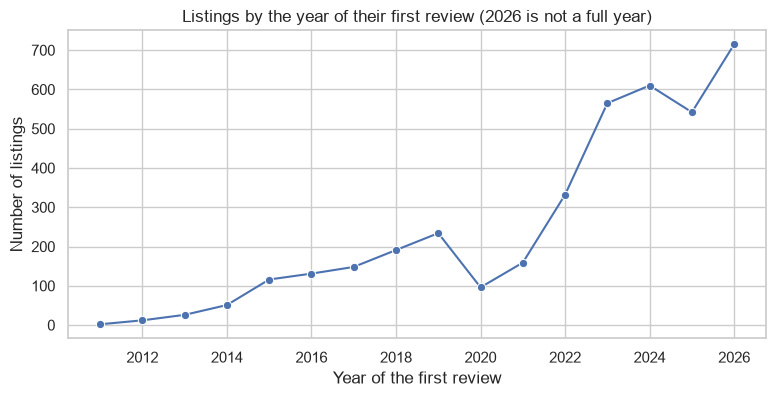

In [19]:
per_year = listings['first_review'].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9,4))

sns.lineplot(x=per_year.index, y=per_year.values, marker='o', ax= ax)

ax.set_title('Listings by the year of their first review (2026 is not a full year)')
ax.set_xlabel('Year of the first review')
ax.set_ylabel('Number of listings')

plt.show()

## A good chart, and a chart that lies

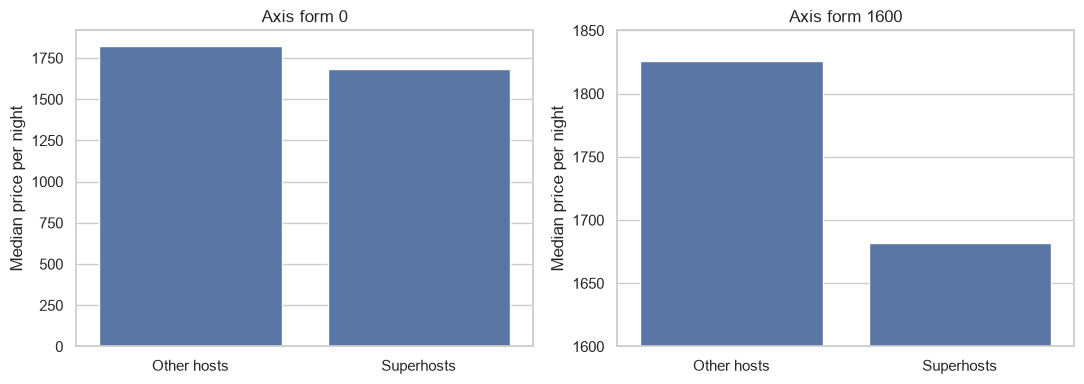

In [20]:
superhost = listings.groupby('host_is_superhost')['price'].median()

fig, axes = plt.subplots(1, 2, figsize= (11, 4))

for ax in axes:
    sns.barplot(x=['Other hosts', 'Superhosts'], y=superhost.values, ax= ax)
    ax.set_ylabel('Median price per night')

axes[0].set_title('Axis form 0')
axes[1].set_title('Axis form 1600')
axes[1].set_ylim(1600, 1850)

plt.tight_layout()
plt.show()

- **A title that says what we see**, not just what it is.
- **Names on both axes**, and the unit when there is one.
- **One colour, unless the colour means something**, and never colour only for decoration.
- **Bars start at zero**, and are sorted.
- **Say what you left out**: the missing values, the cut-off axis, the outliers. And **say how many** listings are behind the picture.
- **Do not draw what you cannot read**: too many categories, too many colours, 3D effects.

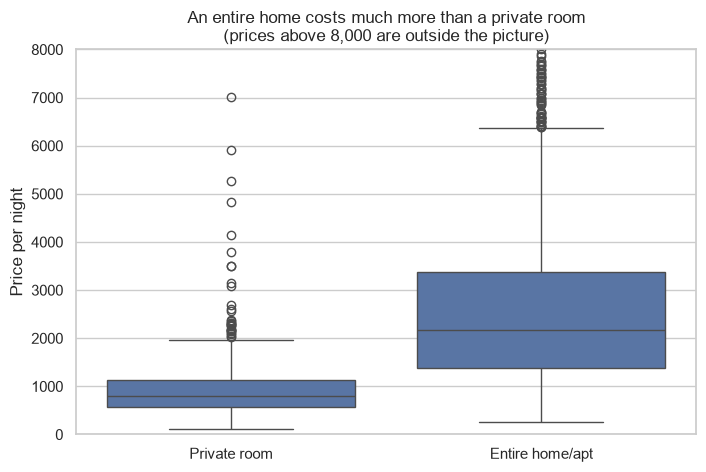

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=two_types, x='room_type', y='price', ax=ax)

ax.set_ylim(0, 8000)
ax.set_title('An entire home costs much more than a private room\n(prices above 8,000 are outside the picture)')
ax.set_xlabel('')
ax.set_ylabel('Price per night')

fig.savefig('price_per_room_type.png', dpi=150, bbox_inches='tight')

plt.show()